### Regressão Logística do zero

A regressão logística estima a probabilidade de uma **variável dependente (Y)** pertencer à **classe 0 ou à classe 1**, com base em uma ou mais **variáveis independentes (X)**. Para isso, utiliza uma combinação linear das variáveis preditoras, caracterizada por um **coeficiente angular (w)** e um **intercepto (b)**. Em seguida, aplica a função *Sigmoid* para converter o resultado em uma probabilidade entre 0 e 1, permitindo determinar a classe prevista a partir de um limiar de decisão.

Este notebook é a continuação do anterior: a regressão logística é implementada em *Python* com a biblioteca *NumPy* (em `src/logistic_regression.py`) e otimizada por **gradiente descendente**, o método generalizável que vimos na regressão linear. Diferente daquele caso, aqui não existe uma fórmula fechada, então o gradiente é o único caminho. Por fim, os resultados são comparados com `sklearn.linear_model.LogisticRegression`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

from src.logistic_regression import RegressaoLogistica

SEED = 42
np.random.seed(SEED)


def avaliar(y, proba):
    # Cross-Entropy e acurácia (limiar de 0.5) a partir das probabilidades previstas para a classe 1.
    return log_loss(y, proba), accuracy_score(y, proba > 0.5)

## Derivação do Gradiente

Queremos uma função que estime o quão bem nosso modelo se ajusta aos dados, de maneira semelhante ao *Mean Squared Error* (MSE) na regressão linear. Dessa vez, porém, como os valores da variável dependente (Y) estarão categorizados (geralmente, 0 para uma classe e 1 para a classe de interesse), utilizaremos outra abordagem.

A melhor forma de começar é pela **função de verossimilhança**, que representa a probabilidade de observarmos determinados dados considerando os parâmetros de um modelo. Para um conjunto de **n amostras independentes**, temos:

$$\text{L}(\theta | \text{dados}) = \prod_{i=1}^{n} P(y_i | \hat{y}_i)$$

Ou seja, multiplicamos as probabilidades de cada observação estar correta segundo o modelo. Não há nada de errado com essa fórmula, mas, quando multiplicamos computacionalmente vários números pequenos, corremos o risco de um *underflow* numérico: o resultado ultrapassa a precisão disponível e é aproximado para zero, comprometendo nossos cálculos.

Por isso, utilizamos a versão logarítmica da verossimilhança:

$$\log(\text{L}) = \sum_{i=1}^{n} \log(P(y_i | \hat{y}_i))$$

Em um problema binário, especificamente, para cada amostra **i**, temos:

$$\text{Se } y_i = 1: \quad P(y_i | \hat{y}_i) = \hat{y}_i \qquad \text{Se } y_i = 0: \quad P(y_i | \hat{y}_i) = 1 - \hat{y}_i$$

Se o modelo prevê uma probabilidade de 0.4 para a classe 1, por exemplo, consequentemente teremos uma probabilidade de 0.6 para a classe 0.

Podemos, então, juntar as duas possibilidades em uma única expressão:

$$LL_i = y_i \cdot \log(\hat{y}_i) + (1-y_i) \cdot \log(1-\hat{y}_i)$$

Se $y_i = 1$, o segundo termo é anulado, restando apenas o primeiro. Da mesma forma, se $y_i = 0$, o primeiro termo é anulado, restando apenas o segundo.

Como a log-verossimilhança deve ser maximizada, multiplicamos o resultado por $-1$ para transformar o problema em uma minimização. Além disso, dividimos por $n$, para que a perda represente a média dos erros e não aumente simplesmente em razão do tamanho do conjunto de dados. Assim, chegamos à **Cross-Entropy**, que utilizaremos para otimizar nossos parâmetros:

$$L = -\frac{1}{n}\sum_{i=1}^{n}[y_i \cdot \log(\hat{y}_i) + (1-y_i) \cdot \log(1-\hat{y}_i)]$$

$$\text{onde}$$

$$\hat{y}_i = \sigma(z_i) = \frac{1}{1 + e^{-z_i}} \quad \text{e} \quad z_i = w \cdot x_i + b$$

Vale ressaltar que, nesse caso, $\hat{y}_i$ representa a saída da função *Sigmoid* aplicada à combinação linear das variáveis independentes. Basicamente, essa função transforma nossos valores em probabilidades entre 0 e 1. Portanto, podemos interpretá-los como a probabilidade de cada observação pertencer à classe 1.

A classificação propriamente dita acontece posteriormente, quando aplicamos um limiar de decisão (geralmente 0.5) para determinar se a observação pertence à classe 0 ou à classe 1. **Esse limiar não faz parte da função Cross-Entropy**, mas sim da etapa de classificação.

Queremos encontrar os valores de **w** e **b** que minimizam $L$. Diferente da regressão linear, igualar as derivadas a zero não leva a uma fórmula fechada (a equação envolve a *Sigmoid* e não tem solução algébrica), então utilizaremos o gradiente descendente, como sugere o título desta seção.

Como $L$ é uma média, seu gradiente é a média dos gradientes de cada amostra. Vamos derivá-los para uma única amostra, cuja perda chamaremos de $\ell$. Pela regra da cadeia, sabemos que:

$$\frac{\partial \ell}{\partial z} = \frac{\partial \ell}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z}$$

Vamos começar por $\frac{\partial \ell}{\partial \hat{y}}$:

$$\frac{\partial \ell}{\partial \hat{y}} = \frac{\partial}{\partial \hat{y}}(-[y \cdot \log(\hat{y}) + (1-y) \cdot \log(1-\hat{y})])$$

$$= -\frac{y}{\hat{y}} + \frac{1-y}{1-\hat{y}}$$

Sendo $\hat{y}(1-\hat{y})$ o denominador comum, multiplicamos a primeira fração por $\frac{1-\hat{y}}{1-\hat{y}}$ e a segunda por $\frac{\hat{y}}{\hat{y}}$. Em seguida, juntamos as frações:

$$= -\frac{y(1-\hat{y}) - (1-y)\hat{y}}{\hat{y}(1-\hat{y})}$$

$$= -\frac{y-y\hat{y}-\hat{y}+y\hat{y}}{\hat{y}(1-\hat{y})}$$

$$= \frac{\hat{y}-y}{\hat{y}(1-\hat{y})}$$

Acabamos de encontrar $\frac{\partial \ell}{\partial \hat{y}}$.

Agora, para $\frac{\partial \hat{y}}{\partial z}$, sabendo que $\hat{y} = \sigma(z)$, temos uma das propriedades mais elegantes da função *Sigmoid*:

$$\frac{\partial \sigma(z)}{\partial z} = \sigma(z)(1-\sigma(z)) = \hat{y}(1-\hat{y})$$

Agora, chegamos a uma das partes mais satisfatórias dessa derivação:

$$\frac{\partial \ell}{\partial z} = \frac{\hat{y}-y}{\hat{y}(1-\hat{y})} \cdot \hat{y}(1-\hat{y})$$

$$\boxed{\frac{\partial \ell}{\partial z} = \hat{y}-y}$$

A partir daqui, não há muito segredo: voltamos a aplicar a regra da cadeia para encontrar os gradientes de **w** e **b**, lembrando que $z = w \cdot x + b$:

$$\frac{\partial \ell}{\partial w} = \frac{\partial \ell}{\partial z} \cdot \frac{\partial z}{\partial w} = (\hat{y}-y) \cdot x \qquad \frac{\partial \ell}{\partial b} = \frac{\partial \ell}{\partial z} \cdot \frac{\partial z}{\partial b} = (\hat{y}-y) \cdot 1$$

Para as **n amostras**, basta tirar a média dos gradientes individuais e chegamos aos gradientes finais de $L$:

$$\boxed{\frac{\partial L}{\partial w} = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)\cdot x_i} \quad \boxed{\frac{\partial L}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)}$$

Note a semelhança com a regressão linear: o gradiente continua sendo "erro vezes entrada", só que o erro agora é $\hat{y}_i - y_i$, calculado com a probabilidade da *Sigmoid*. Como o gradiente aponta na direção de maior crescimento da função de perda, a cada iteração subtraímos os gradientes dos respectivos parâmetros, multiplicados pela taxa de aprendizado *lr*, para caminhar em direção ao mínimo:

$$w \leftarrow w - lr \cdot \frac{\partial L}{\partial w} \qquad b \leftarrow b - lr \cdot \frac{\partial L}{\partial b}$$

Vale destacar que, na regressão logística binária, utilizando a função *Sigmoid* e a *Cross-Entropy*, a função de perda é convexa em relação aos parâmetros $w$ e $b$. Isso significa que não precisamos nos preocupar com mínimos locais distintos do mínimo global.

Para fins de avaliação, além da *Cross-Entropy*, usaremos a **acurácia**: a fração de amostras classificadas corretamente após aplicar o limiar de 0.5. As duas métricas dizem coisas diferentes. A acurácia só olha para qual lado do limiar cada amostra cai, enquanto a *Cross-Entropy* também pune probabilidades erradas ou pouco confiantes. Como referência, um modelo que prevê sempre 0.5 tem *Cross-Entropy* igual a $\ln 2 \approx 0.693$ (o equivalente à previsão ingênua da média no R² da regressão linear).

## Dados

Como o modelo foi desenvolvido para uma única variável independente, usaremos apenas uma característica. Geramos 100 pontos com classes sobrepostas (`class_sep=0.3`) e 15% dos rótulos sorteados aleatoriamente (`flip_y=0.15`), e separamos 20% deles para teste: os modelos só "enxergam" os dados de treino, e os de teste servem para avaliá-los em dados novos.

In [2]:
x, y = make_classification(
    n_features=1,
    n_informative=1,
    n_redundant=0,
    n_clusters_per_class=1,
    n_samples=100,
    weights=[0.5, 0.5],
    flip_y=0.15,
    class_sep=0.3,
    random_state=SEED
)
x = x[:, 0]   # (100, 1) -> (100,)

# Separação treino/teste
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=SEED)

# Modelos
model_gd = RegressaoLogistica()
model_sklearn = LogisticRegression(C=np.inf)   # sem regularização (explicado adiante)

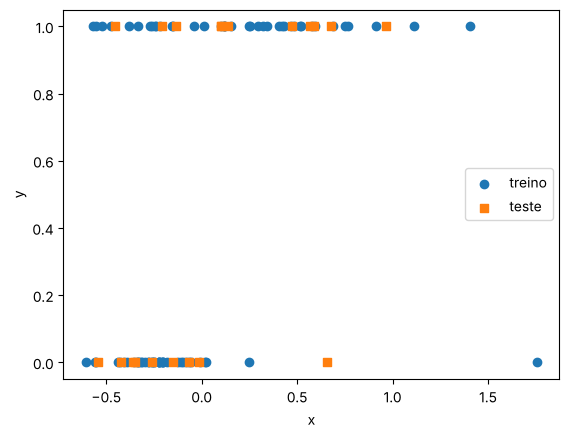

In [3]:
plt.scatter(x_train, y_train, label="treino")
plt.scatter(x_test, y_test, marker="s", label="teste")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## Treinamento com os hiperparâmetros padrão

Agora, vamos testar o modelo criado por mim. É esperado que reproduza resultados semelhantes ao modelo do *scikit-learn*, que veremos adiante.

Vale ressaltar que o método com gradientes usa, por padrão, 100 iterações e uma taxa de aprendizado de 0,01. Isso significa que ele percorre um *loop* cem vezes e, em cada uma delas, subtrai dos parâmetros os respectivos gradientes multiplicados pela taxa de aprendizado. Essa taxa controla o tamanho do passo: se for pequena demais, a convergência é lenta; se for grande demais, os parâmetros podem "pular" o mínimo. Também precisamos conferir se esses valores padrão são suficientes.

In [4]:
model_gd.fit(x_train, y_train)

ce, acc = avaliar(y_test, model_gd.predict_proba(x_test))
print(f"Regressão Logística (gradientes): Cross-Entropy = {ce:.4f} | Acurácia = {acc:.2f}")

Regressão Logística (gradientes): Cross-Entropy = 0.6833 | Acurácia = 0.80


Ambas as métricas acima foram calculadas no **conjunto de teste**. A acurácia parece razoável, mas a *Cross-Entropy* está muito perto de $\ln 2 \approx 0.693$, o valor de um modelo que prevê sempre 0.5. Ou seja, com os hiperparâmetros padrão o modelo mal começou a aprender as probabilidades. Vamos conferir a curva de perda (*loss*) do treino:

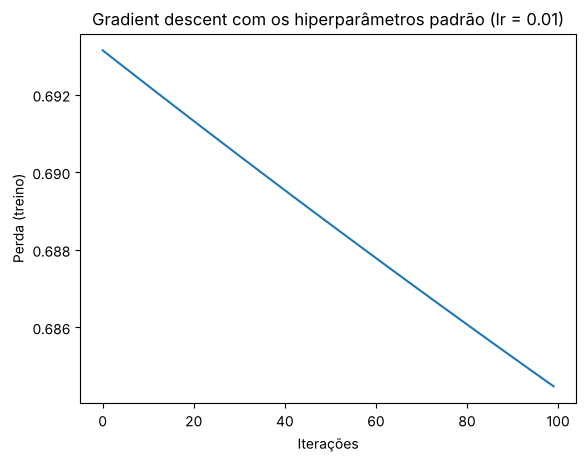

In [5]:
plt.plot(model_gd.loss_history)
plt.xlabel("Iterações")
plt.ylabel("Perda (treino)")
plt.title("Gradient descent com os hiperparâmetros padrão (lr = 0.01)")
plt.show()

## Comparação com o scikit-learn

Agora, vejamos o que o modelo do *scikit-learn* tem a nos dizer. Para usá-lo, precisamos dar à variável independente o formato esperado, uma matriz com uma coluna.

Há ainda um detalhe: por padrão, o `LogisticRegression` aplica regularização L2 (`C = 1.0`), que soma à perda um termo que penaliza pesos grandes. Como o nosso modelo minimiza apenas a *Cross-Entropy*, usamos `C=np.inf` (definido acima) para desligá-la e comparar os dois métodos na mesma função de perda.

In [6]:
X_train = x_train.reshape(-1, 1)
X_test = x_test.reshape(-1, 1)

model_sklearn.fit(X_train, y_train)

ce, acc = avaliar(y_test, model_sklearn.predict_proba(X_test)[:, 1])
print(f"scikit-learn: Cross-Entropy = {ce:.4f} | Acurácia = {acc:.2f}")

scikit-learn: Cross-Entropy = 0.5565 | Acurácia = 0.75


A *Cross-Entropy* do *scikit-learn* é bem menor (aproximadamente 0,56 contra 0,68), ou seja, ele estima melhor as probabilidades. A acurácia, por outro lado, é um pouco menor que a do nosso modelo (0,75 contra 0,80), mas isso equivale a uma única amostra entre as 20 de teste e não indica um modelo pior. Vamos comparar as curvas e, depois, os pesos:

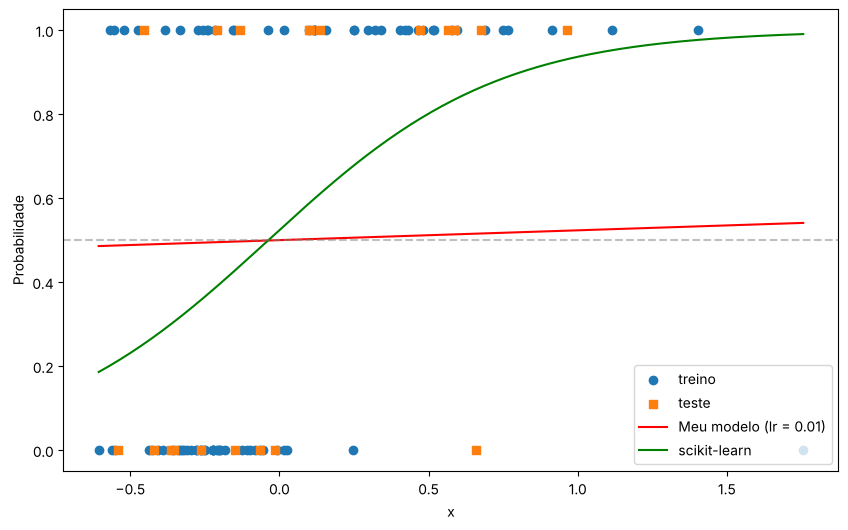

In [7]:
xs = np.linspace(x.min(), x.max(), 200)

plt.figure(figsize=(10, 6))
plt.scatter(x_train, y_train, label="treino")
plt.scatter(x_test, y_test, marker="s", label="teste")
plt.plot(xs, model_gd.predict_proba(xs), color="red", label="Meu modelo (lr = 0.01)")
plt.plot(xs, model_sklearn.predict_proba(xs.reshape(-1, 1))[:, 1], color="green", label="scikit-learn")
plt.axhline(y=0.5, color="gray", linestyle="--", alpha=0.5)
plt.xlabel("x")
plt.ylabel("Probabilidade")
plt.legend()
plt.show()

In [8]:
pesos = {
    "Meu modelo (padrão)": (model_gd.weight, model_gd.bias),
    "scikit-learn":        (model_sklearn.coef_[0][0], model_sklearn.intercept_[0]),
}

for nome, (w, b) in pesos.items():
    print(f"{nome:<20} w = {w:.8f}   b = {b:.8f}")

print()
print(f"Meu modelo bate com o scikit-learn? {np.allclose(pesos['Meu modelo (padrão)'], pesos['scikit-learn'], atol=1e-3)}")

Meu modelo (padrão)  w = 0.09353856   b = -0.00000942
scikit-learn         w = 2.59498657   b = 0.09594401

Meu modelo bate com o scikit-learn? False


Os pesos estão muito distantes ($w \approx 0.09$ contra $w \approx 2.59$): com os hiperparâmetros padrão, nosso modelo parou cedo demais. No gráfico, a *Sigmoid* dele é quase uma reta colada em 0.5, com probabilidades entre aproximadamente 0,49 e 0,54, enquanto a do *scikit-learn* varia por quase toda a faixa de 0 a 1.

Então por que as acurácias são parecidas? Porque a classe prevista depende apenas de qual lado do limiar cada ponto cai, ou seja, do ponto onde a curva cruza 0.5 ($x = -b/w$), e não da inclinação da curva. As duas curvas cruzam 0.5 em pontos muito próximos e, por isso, classificam quase todas as amostras da mesma forma. É exatamente por isso que a acurácia sozinha não basta: a *Cross-Entropy* é que denuncia a diferença entre as probabilidades. Queremos que o nosso gradiente chegue ao mesmo ponto que o *scikit-learn*, então vamos descobrir quantas iterações isso exige.

## Quantas iterações são necessárias?

Como na regressão linear, a curva de perda sozinha não diz se o treino terminou de convergir. Aqui não há solução analítica para servir de referência, mas o *scikit-learn*, que usa outro otimizador (L-BFGS), nos entrega os pesos que minimizam a *Cross-Entropy* de treino. Reaproveitamos, então, a mesma ideia de antes: uma função que treina o modelo com um número crescente de iterações e devolve o menor número para o qual os pesos ficam a menos de `tol` dos pesos do *scikit-learn*.

Pelo mesmo motivo de antes, a referência são os pesos, e não as métricas de teste: escolher hiperparâmetros olhando o conjunto de teste contaminaria a avaliação final.

In [9]:
def iteracoes_ate_convergir(lr, tol=1e-3, passo=100, max_epochs=5000):
    w_ref, b_ref = model_sklearn.coef_[0][0], model_sklearn.intercept_[0]
    for n_epochs in range(passo, max_epochs + 1, passo):
        m = RegressaoLogistica()
        m.fit(x_train, y_train, epochs=n_epochs, learning_rate=lr)
        if abs(m.weight - w_ref) < tol and abs(m.bias - b_ref) < tol:
            return n_epochs
    return None   # não convergiu dentro de max_epochs

In [10]:
for lr in [0.01, 0.1, 0.5, 1.0]:
    n_iter = iteracoes_ate_convergir(lr)
    resultado = f"{n_iter} iterações" if n_iter else "não convergiu em 5000 iterações"
    print(f"Learning rate {lr:<5} -> {resultado}")

Learning rate 0.01  -> não convergiu em 5000 iterações


Learning rate 0.1   -> 3400 iterações
Learning rate 0.5   -> 700 iterações
Learning rate 1.0   -> 400 iterações


Quanto maior a taxa de aprendizado, menos iterações são necessárias. Com o valor padrão (0,01), nem 5000 iterações bastam. Mesmo com `lr = 0.5` são necessárias 700, bem mais que as 100 padrão. Isso acontece porque, perto do mínimo, a curvatura da *Cross-Entropy* é pequena (a derivada da *Sigmoid* vale no máximo 0.25), então os gradientes encolhem e o avanço fica lento, o que pede taxas de aprendizado maiores. Com `lr = 1.0`, bastam 400 iterações. Vamos testar:

In [11]:
model_gd_v2 = RegressaoLogistica()
model_gd_v2.fit(x_train, y_train, epochs=400, learning_rate=1.0)

ce, acc = avaliar(y_test, model_gd_v2.predict_proba(x_test))
print(f"Cross-Entropy (teste): {ce:.4f}")
print(f"Acurácia (teste): {acc:.2f}")

Cross-Entropy (teste): 0.5565
Acurácia (teste): 0.75


Com essa mudança, o gradiente atinge a mesma *Cross-Entropy* e a mesma acurácia do *scikit-learn*. Vamos comparar os pesos:

In [12]:
pesos["Gradient descent (lr = 1.0)"] = (model_gd_v2.weight, model_gd_v2.bias)

for nome, (w, b) in pesos.items():
    print(f"{nome:<28} w = {w:.8f}   b = {b:.8f}")

print()
print(f"Gradient descent (lr = 1.0) bate com o scikit-learn? {np.allclose(pesos['Gradient descent (lr = 1.0)'], pesos['scikit-learn'], atol=1e-3)}")

Meu modelo (padrão)          w = 0.09353856   b = -0.00000942
scikit-learn                 w = 2.59498657   b = 0.09594401
Gradient descent (lr = 1.0)  w = 2.59497239   b = 0.09595603

Gradient descent (lr = 1.0) bate com o scikit-learn? True


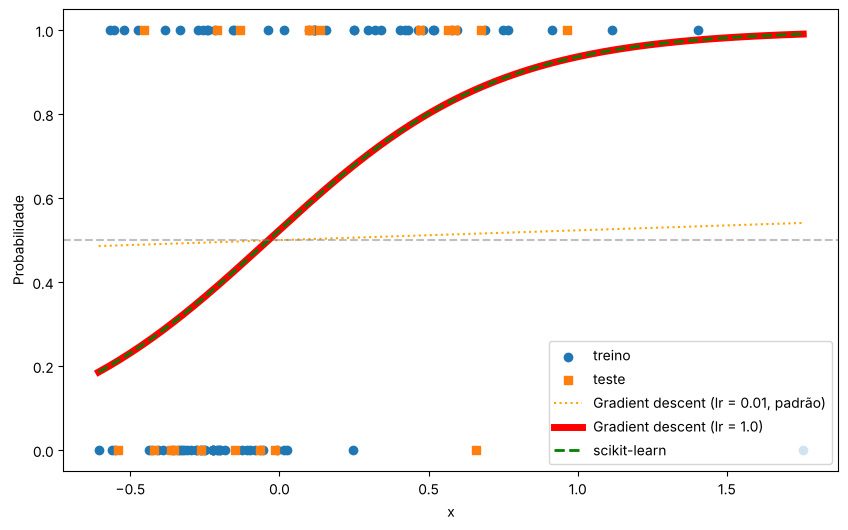

In [13]:
plt.figure(figsize=(10, 6))
plt.scatter(x_train, y_train, label="treino")
plt.scatter(x_test, y_test, marker="s", label="teste")
plt.plot(xs, model_gd.predict_proba(xs), color="orange", linewidth=1.5, linestyle=":", label="Gradient descent (lr = 0.01, padrão)")
plt.plot(xs, model_gd_v2.predict_proba(xs), color="red", linewidth=5, label="Gradient descent (lr = 1.0)")
plt.plot(xs, model_sklearn.predict_proba(xs.reshape(-1, 1))[:, 1], color="green", linewidth=2, linestyle="--", label="scikit-learn")
plt.axhline(y=0.5, color="gray", linestyle="--", alpha=0.5)
plt.xlabel("x")
plt.ylabel("Probabilidade")
plt.legend()
plt.show()

Agora os pesos coincidem (a diferença é da ordem de $10^{-5}$) e as curvas se sobrepõem, por isso foram desenhadas com espessuras e estilos diferentes para que todas fiquem visíveis. Técnicas diferentes (gradiente descendente e L-BFGS) convergiram para o mesmo resultado, afinal, minimizam a mesma função de perda. Isso indica que a implementação foi desenvolvida com sucesso.

Vale notar que o modelo padrão tinha acurácia maior que a do modelo convergido (0,80 contra 0,75), mas probabilidades muito piores (*Cross-Entropy* de 0,68 contra 0,56). Como as probabilidades são o objetivo da regressão logística, a *Cross-Entropy* é o que realmente mostra o quanto o modelo aprendeu.

## Limitações

- **Uma única variável e duas classes**: a implementação só trata uma característica e o caso binário. O passo natural é vetorizar (o gradiente vira $\frac{1}{n}X^T(\hat{y}-y)$) e, para várias classes, trocar a Sigmoid pela Softmax.
- **Sem regularização**: se as classes forem perfeitamente separáveis, os pesos crescem indefinidamente, porque a perda não tem mínimo. É por isso que o scikit-learn aplica L2 por padrão, e foi o que desligamos para comparar.
- **Gradiente**: depende de lr e do número de iterações, e foi lento aqui (400 iterações com lr = 1.0). Também é sensível à escala das variáveis, como vimos no 01.
- **Limiar fixo em 0.5**: é razoável com classes balanceadas, mas com classes desbalanceadas ou erros de custos diferentes ele deveria ser ajustado.
- **Teste pequeno**: são só 20 amostras, e uma amostra vale 0,05 de acurácia. As diferenças entre modelos nessa métrica são ruído, e uma validação cruzada daria uma estimativa mais firme.

## Conclusão

- O gradiente descendente (com lr adequado) e o scikit-learn sem regularização chegaram aos mesmos pesos, com diferença da ordem de $10^{-5}$.
Com os hiperparâmetros padrão, o modelo não convergiu: com lr = 0.01, nem 5000 iterações bastam. Com lr = 1.0, bastam 400.
- A acurácia enganou: o modelo não convergido teve 0,80 contra 0,75, mas sua Cross-Entropy (0,68) estava quase em $\ln 2$, a de um modelo que prevê sempre 0.5, contra 0,56 do modelo convergido.
- Os pesos do scikit-learn com as configurações padrão diferem dos nossos por causa da regularização L2, e não por erro de implementação.